# 05 - Preprocessing and Baseline Modelling (Phase 4)
**Question:** how accurately can we estimate the probability that an unseen student will be placed?
This phase does both **classification** and **probability estimation**, and judges models primarily on probability quality
(ROC-AUC, log loss, Brier score) rather than accuracy alone.

## Data policy (enforced in code)
| Split | File | Use in this notebook |
|---|---|---|
| TRAIN | `data/processed/train.csv` | fit every learned preprocessing step and every model |
| VALIDATION | `data/processed/validation.csv` | compare variants, choose hyper-parameters, provisional model selection |
| TEST | `data/processed/test.csv` | **never opened.** An audit hook records every file this notebook opens and a final assertion proves `test.csv` (processed or raw) was not read. Reserved for Phase 6. |

The raw supplied splits and the full `modeling_dataset.csv` are also not used. The classification threshold stays at the default 0.5 (no threshold tuning), and calibration is inspected in Phase 5.

*Disclosure:* the Phase 2-3 EDA/statistics used all modelling rows (including those now in the test split) to describe associations. They informed the choice to compare
numeric vs categorical coding of the count variables, but no model was fitted or scored on test rows, and this notebook's decisions rest on train/validation only.

## Method summary
- **Two preprocessing variants**, each in a scikit-learn `Pipeline` + `ColumnTransformer`, so scaling/encoding parameters are learned from the training data only inside the pipeline.
- **Models:** regularised logistic regression (plus a `class_weight="balanced"` comparison), decision tree, random forest, gradient boosting; each with a small, explicit validation-based search.
- **Within-family selection rule:** lowest validation log loss (the proper scoring rule closest to the project goal); ties broken by ROC-AUC. The complete search grids are saved so the extent of selection on validation is transparent.
- **Uncertainty:** the validation set has only about 1,487 students, so 95% bootstrap CIs (1,000 resamples) are attached to metrics, and *paired* bootstrap is used to compare models fairly.

In [1]:
import warnings
warnings.simplefilter("always")
import sys, json, itertools, time
from pathlib import Path

# ---- audit hook: records every file opened by this process so we can PROVE the test set was never read ----
_OPENED = []
def _audit(event, args):
    if event == "open":
        try: _OPENED.append(str(args[0]))
        except Exception: pass
sys.addaudithook(_audit)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss,
                             brier_score_loss, confusion_matrix, roc_curve)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models" / "phase4"
MET = ROOT / "results" / "metrics" / "modeling"
FIG = ROOT / "results" / "figures" / "modeling"
for d in (MODELS, MET, FIG): d.mkdir(parents=True, exist_ok=True)

SEED = 42
B_BOOT = 1000
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e6ea", "axes.edgecolor": "#9aa3ad", "axes.titlesize": 12,
                                      "axes.titleweight": "semibold", "axes.labelsize": 10.5, "figure.dpi": 110})
PLACED_C, NOT_C, NEUTRAL = "#2166ac", "#e08214", "#6b7785"
FAM_C = {"LR": "#0072B2", "DT": "#E69F00", "RF": "#009E73", "GB": "#D55E00"}      # Okabe-Ito, colour-blind safe
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
def write_json(obj, path):
    with open(path, "w", encoding="utf-8") as fh: json.dump(obj, fh, indent=2, default=str)
print("scikit-learn", sklearn.__version__, "| seed", SEED)

scikit-learn 1.9.1 | seed 42


## 1. Load TRAIN and VALIDATION only; features and target

In [2]:
TARGET = "PlacementStatus"
CONT = ["CGPA", "AptitudeTestScore", "SoftSkillsRating", "SSC_Marks", "HSC_Marks"]
COUNT = ["Internships", "Projects", "Workshops/Certifications"]
BIN = ["ExtracurricularActivities", "PlacementTraining"]
FEATURES = ["CGPA", "Internships", "Projects", "Workshops/Certifications", "AptitudeTestScore", "SoftSkillsRating",
            "ExtracurricularActivities", "PlacementTraining", "SSC_Marks", "HSC_Marks"]
assert sorted(FEATURES) == sorted(CONT + COUNT + BIN) and len(FEATURES) == 10

train = pd.read_csv(PROC / "train.csv"); val = pd.read_csv(PROC / "validation.csv")
for name, d in [("train", train), ("validation", val)]:
    assert list(d.columns) == FEATURES + [TARGET] or sorted(d.columns) == sorted(FEATURES + [TARGET]), name
    assert d.isna().sum().sum() == 0 and set(d[TARGET]) == {"Placed", "NotPlaced"}, name
# leakage guard between the two splits we use
tp = set(map(tuple, train[FEATURES].values)); vp = set(map(tuple, val[FEATURES].values))
assert not (tp & vp), "feature-profile overlap between train and validation"

X_train, X_val = train[FEATURES].copy(), val[FEATURES].copy()
y_train = (train[TARGET] == "Placed").astype(int).to_numpy()     # Placed = 1, NotPlaced = 0
y_val = (val[TARGET] == "Placed").astype(int).to_numpy()
for c in COUNT: X_train[c] = X_train[c].astype(int); X_val[c] = X_val[c].astype(int)
print(f"train {X_train.shape}, Placed rate {y_train.mean():.4f}   |   validation {X_val.shape}, Placed rate {y_val.mean():.4f}")
print("Predictors:", FEATURES); print("No ID/index/source/split columns are used; target encoded Placed=1, NotPlaced=0.")

train (6938, 10), Placed rate 0.4155   |   validation (1487, 10), Placed rate 0.4156
Predictors: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks']
No ID/index/source/split columns are used; target encoded Placed=1, NotPlaced=0.


## 2. Preprocessing variants
**Variant A - numeric counts.** Internships, Projects and Workshops/Certifications stay numeric; all eight numeric columns are standardised (for logistic regression); the two binary predictors are one-hot encoded.

**Variant B - categorical counts.** The three count variables are one-hot encoded together with the two binary predictors (5 categorical variables); only the five scale-type variables (CGPA, aptitude, soft skills, SSC, HSC) are standardised.

**Reference categories (logistic regression).** One level per categorical variable is dropped so coefficients are contrasts against that reference. Binary variables use `No`. For the count variables the reference is the **most frequent level in TRAIN**, so every coefficient is compared with a large group
(e.g. only a handful of training students have Projects = 0, which would make a poor reference). **Tree models are not standardised** (splits are scale-invariant) and keep all one-hot levels.
No imputation is used: there are no missing values.

In [3]:
REFS = {c: int(X_train[c].mode().iloc[0]) for c in COUNT}          # learned from TRAIN only
print("Reference levels for count variables (train mode):", REFS, "| binary reference: 'No'")
print("Train level counts:", {c: X_train[c].value_counts().sort_index().to_dict() for c in COUNT})

def make_preprocessor(variant, scale, drop_ref):
    # variant 'A': counts numeric ; 'B': counts one-hot.  scale: StandardScaler on numeric columns ; drop_ref: drop reference level (LR)
    bin_enc = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="error")        # reference = 'No'
    scaler = StandardScaler() if scale else "passthrough"
    if variant == "A":
        parts = [("num", scaler, CONT + COUNT), ("bin", bin_enc, BIN)]
    else:
        cnt_enc = OneHotEncoder(drop=[REFS[c] for c in COUNT] if drop_ref else None, sparse_output=False, handle_unknown="error")
        parts = [("num", scaler, CONT), ("cnt", cnt_enc, COUNT), ("bin", bin_enc, BIN)]
    return ColumnTransformer(parts, verbose_feature_names_out=False).set_output(transform="pandas")

def make_pipeline(kind, variant, **params):
    if kind == "LR":
        pre = make_preprocessor(variant, scale=True, drop_ref=True)
        model = LogisticRegression(l1_ratio=0, solver="lbfgs", max_iter=5000, random_state=SEED, **params)   # l1_ratio=0 == L2 (sklearn>=1.8 spelling of penalty='l2')
    else:
        pre = make_preprocessor(variant, scale=False, drop_ref=False)
        cls = {"DT": DecisionTreeClassifier, "RF": RandomForestClassifier, "GB": GradientBoostingClassifier}[kind]
        extra = {"n_jobs": -1} if kind == "RF" else {}
        model = cls(random_state=SEED, **extra, **params)
    return Pipeline([("prep", pre), ("model", model)])

# demonstration: learned parameters come from TRAIN only
demo = make_preprocessor("A", True, True).fit(X_train)
sc = demo.named_transformers_["num"]
assert np.allclose(sc.mean_, X_train[CONT + COUNT].mean().to_numpy())
assert not np.allclose(sc.mean_, X_val[CONT + COUNT].mean().to_numpy()), "scaler appears to have seen validation data"
print("\nScaler means equal TRAIN means (not validation means) -> preprocessing is fitted on train only.")
for v in ["A", "B"]:
    print(f"\nVariant {v} output columns ({'LR' if True else ''}, reference dropped):", list(make_preprocessor(v, True, True).fit(X_train).get_feature_names_out()))

Reference levels for count variables (train mode): {'Internships': 1, 'Projects': 3, 'Workshops/Certifications': 0} | binary reference: 'No'
Train level counts: {'Internships': {0: 1367, 1: 3886, 2: 1685}, 'Projects': {0: 19, 1: 2466, 2: 1780, 3: 2673}, 'Workshops/Certifications': {0: 2592, 1: 1868, 2: 2270, 3: 208}}

Scaler means equal TRAIN means (not validation means) -> preprocessing is fitted on train only.

Variant A output columns (LR, reference dropped): ['CGPA', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks', 'Internships', 'Projects', 'Workshops/Certifications', 'ExtracurricularActivities_Yes', 'PlacementTraining_Yes']

Variant B output columns (LR, reference dropped): ['CGPA', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks', 'Internships_0', 'Internships_2', 'Projects_0', 'Projects_1', 'Projects_2', 'Workshops/Certifications_1', 'Workshops/Certifications_2', 'Workshops/Certifications_3', 'ExtracurricularActivities_Yes', 'PlacementTraining

## 3. Metric helpers and reference baseline

In [4]:
def evaluate(p, y, thr=0.5):
    pred = (p >= thr).astype(int)           # default threshold, deliberately NOT tuned
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p)}

def fit_score(pipe):
    pipe.fit(X_train, y_train)
    return pipe, pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_val)[:, 1]

dummy, p_tr_d, p_va_d = fit_score(Pipeline([("model", DummyClassifier(strategy="prior"))]))
# (Dummy gets raw frame but ignores it)
base_val = evaluate(p_va_d, y_val)
print("Reference: always predict the TRAIN placement rate (%.3f) -> validation" % y_train.mean())
pd.Series(base_val).round(4)

Reference: always predict the TRAIN placement rate (0.416) -> validation


accuracy     0.5844
precision    0.0000
recall       0.0000
f1           0.0000
roc_auc      0.5000
log_loss     0.6788
brier        0.2429
dtype: float64

## 4. Baseline 1 - regularised logistic regression
L2-regularised (`C = 1.0`, `lbfgs`, `max_iter = 5000`), fitted on both preprocessing variants. A `class_weight="balanced"` version of each is trained **only as a comparison**: re-weighting classes deliberately shifts predicted probabilities away from the true base rate, so it is not eligible for the final choice (the project goal is probability estimation).

In [5]:
REG = {}          # model_id -> dict(pipe, p_train, p_val, family, variant, config, label)
def register(mid, family, variant, label, config, pipe, ptr, pva):
    REG[mid] = dict(family=family, variant=variant, label=label, config=config, pipe=pipe, p_train=ptr, p_val=pva)

for v in ["A", "B"]:
    for cw, tag in [(None, ""), ("balanced", "_balanced")]:
        pipe, ptr, pva = fit_score(make_pipeline("LR", v, C=1.0, class_weight=cw))
        assert pipe.named_steps["model"].n_iter_[0] < 5000, "LR did not converge"
        register(f"LR_{v}{tag}", "LR", v, "Logistic regression" + (" (balanced)" if cw else ""), {"C": 1.0, "class_weight": cw}, pipe, ptr, pva)
print("Logistic regression fitted (converged) for variants A/B, plain and balanced.")
pd.DataFrame({k: evaluate(r["p_val"], y_val) for k, r in REG.items() if r["family"] == "LR"}).T.round(4)

Logistic regression fitted (converged) for variants A/B, plain and balanced.


,accuracy,precision,recall,f1,roc_auc,log_loss,brier
LR_A,0.8030,0.7660,0.7573,0.7616,0.8694,0.4457,0.1424
LR_A_balanced,0.7929,0.7286,0.7994,0.7623,0.8694,0.4520,0.1461
LR_B,0.8016,0.7723,0.7411,0.7564,0.8717,0.4408,0.1409
LR_B_balanced,0.7949,0.7339,0.7945,0.7630,0.8718,0.4469,0.1442


In [6]:
# Sensitivity of validation log loss to the regularisation strength (reported only; C = 1.0 is kept as the baseline)
rows = []
for v in ["A", "B"]:
    for C_ in [0.01, 0.1, 1.0, 10.0, 100.0]:
        p = make_pipeline("LR", v, C=C_).fit(X_train, y_train).predict_proba(X_val)[:, 1]
        rows.append({"variant": v, "C": C_, **{k: evaluate(p, y_val)[k] for k in ["roc_auc", "log_loss", "brier"]}})
c_sens = pd.DataFrame(rows); c_sens.to_csv(MET / "05_lr_C_sensitivity.csv", index=False)
c_sens.pivot(index="C", columns="variant", values="log_loss").round(4)

variant,A,B
C,,
0.01,0.4479,0.4447
0.10,0.4457,0.4411
1.00,0.4457,0.4408
10.00,0.4457,0.4408
100.00,0.4457,0.4408


## 5. Baseline 2 - decision tree
Controlled search: `max_depth` in {3, 5, 7, None} x `min_samples_leaf` in {1, 5, 10} (12 configurations per variant), Gini criterion. Selection per variant: lowest validation log loss.

In [7]:
GRIDS = []                  # every configuration tried, for transparency
def run_grid(kind, variant, grid, label):
    keys = list(grid); best = None
    for vals in itertools.product(*[grid[k] for k in keys]):
        cfg = dict(zip(keys, vals)); t0 = time.time()
        pipe, ptr, pva = fit_score(make_pipeline(kind, variant, **cfg))
        m = evaluate(pva, y_val); mt = evaluate(ptr, y_train)
        GRIDS.append({"family": kind, "variant": variant, "config": json.dumps(cfg, default=str), **{f"val_{k}": v for k, v in m.items()},
                      "train_roc_auc": mt["roc_auc"], "train_log_loss": mt["log_loss"], "fit_seconds": round(time.time() - t0, 2)})
        key = (m["log_loss"], -m["roc_auc"])
        if best is None or key < best[0]: best = (key, cfg, pipe, ptr, pva)
    _, cfg, pipe, ptr, pva = best
    register(f"{kind}_{variant}", kind, variant, label, cfg, pipe, ptr, pva)
    return cfg

dt_grid = {"max_depth": [3, 5, 7, None], "min_samples_leaf": [1, 5, 10]}
for v in ["A", "B"]: print(f"DT variant {v} selected:", run_grid("DT", v, dt_grid, "Decision tree"))
g = pd.DataFrame(GRIDS); g[g.family == "DT"].assign(config=lambda d: d.config).pivot_table(index="config", columns="variant", values="val_log_loss").round(4)

DT variant A selected: {'max_depth': 3, 'min_samples_leaf': 1}


DT variant B selected: {'max_depth': 5, 'min_samples_leaf': 5}


variant,A,B
config,,
"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.4953,0.4914
"{""max_depth"": 3, ""min_samples_leaf"": 1}",0.4953,0.4914
"{""max_depth"": 3, ""min_samples_leaf"": 5}",0.4953,0.4914
"{""max_depth"": 5, ""min_samples_leaf"": 10}",0.5252,0.4806
"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.5481,0.5035
"{""max_depth"": 5, ""min_samples_leaf"": 5}",0.5245,0.4799
"{""max_depth"": 7, ""min_samples_leaf"": 10}",0.7196,0.7176
"{""max_depth"": 7, ""min_samples_leaf"": 1}",0.7462,0.9545
"{""max_depth"": 7, ""min_samples_leaf"": 5}",0.7870,0.8277


## 6. Model 3 - random forest
`n_estimators = 300`; searched: `max_depth` in {5, 10, None}, `min_samples_leaf` in {1, 5, 10}, `max_features` in {"sqrt", 0.5} (18 configurations per variant).

In [8]:
rf_grid = {"n_estimators": [300], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 10], "max_features": ["sqrt", 0.5]}
for v in ["A", "B"]: print(f"RF variant {v} selected:", run_grid("RF", v, rf_grid, "Random forest"))
g = pd.DataFrame(GRIDS); g[g.family == "RF"].pivot_table(index="config", columns="variant", values="val_log_loss").round(4).sort_values("A").head(8)

RF variant A selected: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 10, 'max_features': 'sqrt'}


RF variant B selected: {'n_estimators': 300, 'max_depth': 10, 'min_samples_leaf': 10, 'max_features': 'sqrt'}


variant,A,B
config,,
"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10, ""max_features"": ""sqrt""}",0.4454,0.4438
"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 10, ""max_features"": ""sqrt""}",0.4457,0.4432
"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 5, ""max_features"": ""sqrt""}",0.4488,0.4442
"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 5, ""max_features"": ""sqrt""}",0.4491,0.4462
"{""n_estimators"": 300, ""max_depth"": 10, ""min_samples_leaf"": 10, ""max_features"": 0.5}",0.4492,0.4470
"{""n_estimators"": 300, ""max_depth"": null, ""min_samples_leaf"": 10, ""max_features"": 0.5}",0.4502,0.4482
"{""n_estimators"": 300, ""max_depth"": 5, ""min_samples_leaf"": 10, ""max_features"": ""sqrt""}",0.4508,0.4508
"{""n_estimators"": 300, ""max_depth"": 5, ""min_samples_leaf"": 5, ""max_features"": ""sqrt""}",0.4509,0.4508


## 7. Model 4 - gradient boosting
Searched: `n_estimators` in {100, 300}, `learning_rate` in {0.05, 0.1}, `max_depth` in {2, 3}, `min_samples_leaf` in {1, 20} (16 configurations per variant).

In [9]:
gb_grid = {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3], "min_samples_leaf": [1, 20]}
for v in ["A", "B"]: print(f"GB variant {v} selected:", run_grid("GB", v, gb_grid, "Gradient boosting"))
grids = pd.DataFrame(GRIDS); grids.to_csv(MET / "05_tuning_grids.csv", index=False)
print("\nConfigurations evaluated:", grids.groupby(["family", "variant"]).size().to_dict())
grids[grids.family == "GB"].pivot_table(index="config", columns="variant", values="val_log_loss").round(4).sort_values("A").head(8)

GB variant A selected: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1}


GB variant B selected: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1}

Configurations evaluated: {('DT', 'A'): 12, ('DT', 'B'): 12, ('GB', 'A'): 16, ('GB', 'B'): 16, ('RF', 'A'): 18, ('RF', 'B'): 18}


variant,A,B
config,,
"{""n_estimators"": 100, ""learning_rate"": 0.1, ""max_depth"": 2, ""min_samples_leaf"": 1}",0.4417,0.4416
"{""n_estimators"": 300, ""learning_rate"": 0.05, ""max_depth"": 2, ""min_samples_leaf"": 1}",0.4425,0.4413
"{""n_estimators"": 100, ""learning_rate"": 0.1, ""max_depth"": 2, ""min_samples_leaf"": 20}",0.4431,0.4418
"{""n_estimators"": 300, ""learning_rate"": 0.05, ""max_depth"": 2, ""min_samples_leaf"": 20}",0.4439,0.4424
"{""n_estimators"": 300, ""learning_rate"": 0.1, ""max_depth"": 2, ""min_samples_leaf"": 1}",0.4444,0.4454
"{""n_estimators"": 100, ""learning_rate"": 0.05, ""max_depth"": 2, ""min_samples_leaf"": 1}",0.4451,0.4443
"{""n_estimators"": 100, ""learning_rate"": 0.05, ""max_depth"": 3, ""min_samples_leaf"": 1}",0.4454,0.4432
"{""n_estimators"": 100, ""learning_rate"": 0.05, ""max_depth"": 2, ""min_samples_leaf"": 20}",0.4454,0.4448


## 8. Validation model comparison
All selected configurations, default threshold 0.5. 95% CIs come from 1,000 bootstrap resamples of the validation students (the same resamples for every model, which also allows *paired* comparisons).

In [10]:
order = ["LR_A", "LR_B", "LR_A_balanced", "LR_B_balanced", "DT_A", "DT_B", "RF_A", "RF_B", "GB_A", "GB_B"]
assert set(order) == set(REG)
EPS = 1e-15
def ll_vec(p): q = np.clip(p, EPS, 1 - EPS); return -(y_val * np.log(q) + (1 - y_val) * np.log(1 - q))
rng = np.random.default_rng(SEED); n_val = len(y_val); IDX = rng.integers(0, n_val, (B_BOOT, n_val))     # shared resamples (paired)
BOOT = {}
for mid in order + ["DUMMY"]:
    p = p_va_d if mid == "DUMMY" else REG[mid]["p_val"]
    BOOT[mid] = {"auc": np.array([roc_auc_score(y_val[i], p[i]) for i in IDX]),
                 "ll": ll_vec(p)[IDX].mean(axis=1), "brier": ((p - y_val) ** 2)[IDX].mean(axis=1)} if mid != "DUMMY" else \
                {"auc": np.full(B_BOOT, 0.5), "ll": ll_vec(p)[IDX].mean(axis=1), "brier": ((p - y_val) ** 2)[IDX].mean(axis=1)}
ci = lambda a: np.percentile(a, [2.5, 97.5])

def cfg_text(r):
    c = {k: v for k, v in r["config"].items() if k not in ("n_estimators",) or r["family"] == "GB"}
    return ", ".join(f"{k}={v}" for k, v in r["config"].items())
rows = []
for mid in order:
    r = REG[mid]; m = evaluate(r["p_val"], y_val)
    rows.append({"model_id": mid, "Model": r["label"], "Feature representation": "A: numeric counts" if r["variant"] == "A" else "B: categorical counts",
                 "Config": cfg_text(r), **{k: m[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "log_loss", "brier"]},
                 "auc_ci_lo": ci(BOOT[mid]["auc"])[0], "auc_ci_hi": ci(BOOT[mid]["auc"])[1], "ll_ci_lo": ci(BOOT[mid]["ll"])[0], "ll_ci_hi": ci(BOOT[mid]["ll"])[1],
                 "brier_ci_lo": ci(BOOT[mid]["brier"])[0], "brier_ci_hi": ci(BOOT[mid]["brier"])[1],
                 "mean_pred": r["p_val"].mean(), "observed_rate": y_val.mean()})
rows.append({"model_id": "DUMMY", "Model": "Reference: train placement rate", "Feature representation": "-", "Config": "strategy=prior",
             **{k: base_val[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "log_loss", "brier"]},
             "ll_ci_lo": ci(BOOT["DUMMY"]["ll"])[0], "ll_ci_hi": ci(BOOT["DUMMY"]["ll"])[1], "brier_ci_lo": ci(BOOT["DUMMY"]["brier"])[0],
             "brier_ci_hi": ci(BOOT["DUMMY"]["brier"])[1], "mean_pred": p_va_d.mean(), "observed_rate": y_val.mean()})
results = pd.DataFrame(rows)
results["brier_skill_vs_base_rate"] = 1 - results.brier / base_val["brier"]
results.to_csv(MET / "05_validation_results.csv", index=False)
cols = ["Model", "Feature representation", "accuracy", "precision", "recall", "f1", "roc_auc", "log_loss", "brier"]
results[cols].round(4)

,Model,Feature representation,accuracy,precision,recall,f1,roc_auc,log_loss,brier
0,Logistic regression,A: numeric counts,0.8030,0.7660,0.7573,0.7616,0.8694,0.4457,0.1424
1,Logistic regression,B: categorical counts,0.8016,0.7723,0.7411,0.7564,0.8717,0.4408,0.1409
2,Logistic regression (balanced),A: numeric counts,0.7929,0.7286,0.7994,0.7623,0.8694,0.4520,0.1461
3,Logistic regression (balanced),B: categorical counts,0.7949,0.7339,0.7945,0.7630,0.8718,0.4469,0.1442
4,Decision tree,A: numeric counts,0.7673,0.7179,0.7249,0.7214,0.8273,0.4953,0.1608
5,Decision tree,B: categorical counts,0.7761,0.7111,0.7767,0.7425,0.8464,0.4799,0.1551
6,Random forest,A: numeric counts,0.8050,0.7898,0.7233,0.7551,0.8680,0.4454,0.1440
7,Random forest,B: categorical counts,0.8003,0.7831,0.7184,0.7494,0.8693,0.4432,0.1431
8,Gradient boosting,A: numeric counts,0.8009,0.7805,0.7249,0.7517,0.8704,0.4417,0.1418
9,Gradient boosting,B: categorical counts,0.8056,0.7861,0.7314,0.7578,0.8706,0.4413,0.1417


In [11]:
print("Selected hyper-parameters per model:")
for mid in order: print(f"  {mid:15s} {cfg_text(REG[mid])}")
print("\n95% bootstrap CIs (validation):")
results.set_index("model_id")[["roc_auc", "auc_ci_lo", "auc_ci_hi", "log_loss", "ll_ci_lo", "ll_ci_hi", "brier", "brier_ci_lo", "brier_ci_hi"]].round(4)

Selected hyper-parameters per model:
  LR_A            C=1.0, class_weight=None
  LR_B            C=1.0, class_weight=None
  LR_A_balanced   C=1.0, class_weight=balanced
  LR_B_balanced   C=1.0, class_weight=balanced
  DT_A            max_depth=3, min_samples_leaf=1
  DT_B            max_depth=5, min_samples_leaf=5
  RF_A            n_estimators=300, max_depth=None, min_samples_leaf=10, max_features=sqrt
  RF_B            n_estimators=300, max_depth=10, min_samples_leaf=10, max_features=sqrt
  GB_A            n_estimators=100, learning_rate=0.1, max_depth=2, min_samples_leaf=1
  GB_B            n_estimators=300, learning_rate=0.05, max_depth=2, min_samples_leaf=1

95% bootstrap CIs (validation):


,roc_auc,auc_ci_lo,auc_ci_hi,log_loss,ll_ci_lo,ll_ci_hi,brier,brier_ci_lo,brier_ci_hi
model_id,,,,,,,,,
LR_A,0.8694,0.8523,0.8875,0.4457,0.4178,0.4749,0.1424,0.1322,0.1532
LR_B,0.8717,0.8543,0.8904,0.4408,0.4119,0.4703,0.1409,0.1301,0.1516
LR_A_balanced,0.8694,0.8523,0.8875,0.4520,0.4237,0.4788,0.1461,0.1355,0.1564
LR_B_balanced,0.8718,0.8543,0.8905,0.4469,0.4185,0.4742,0.1442,0.1331,0.1545
DT_A,0.8273,0.8061,0.8470,0.4953,0.4682,0.5262,0.1608,0.1505,0.1722
DT_B,0.8464,0.8272,0.8656,0.4799,0.4514,0.5107,0.1551,0.1447,0.1660
RF_A,0.8680,0.8497,0.8864,0.4454,0.4192,0.4734,0.1440,0.1343,0.1540
RF_B,0.8693,0.8517,0.8879,0.4432,0.4171,0.4708,0.1431,0.1333,0.1534
GB_A,0.8704,0.8528,0.8889,0.4417,0.4140,0.4694,0.1418,0.1312,0.1525


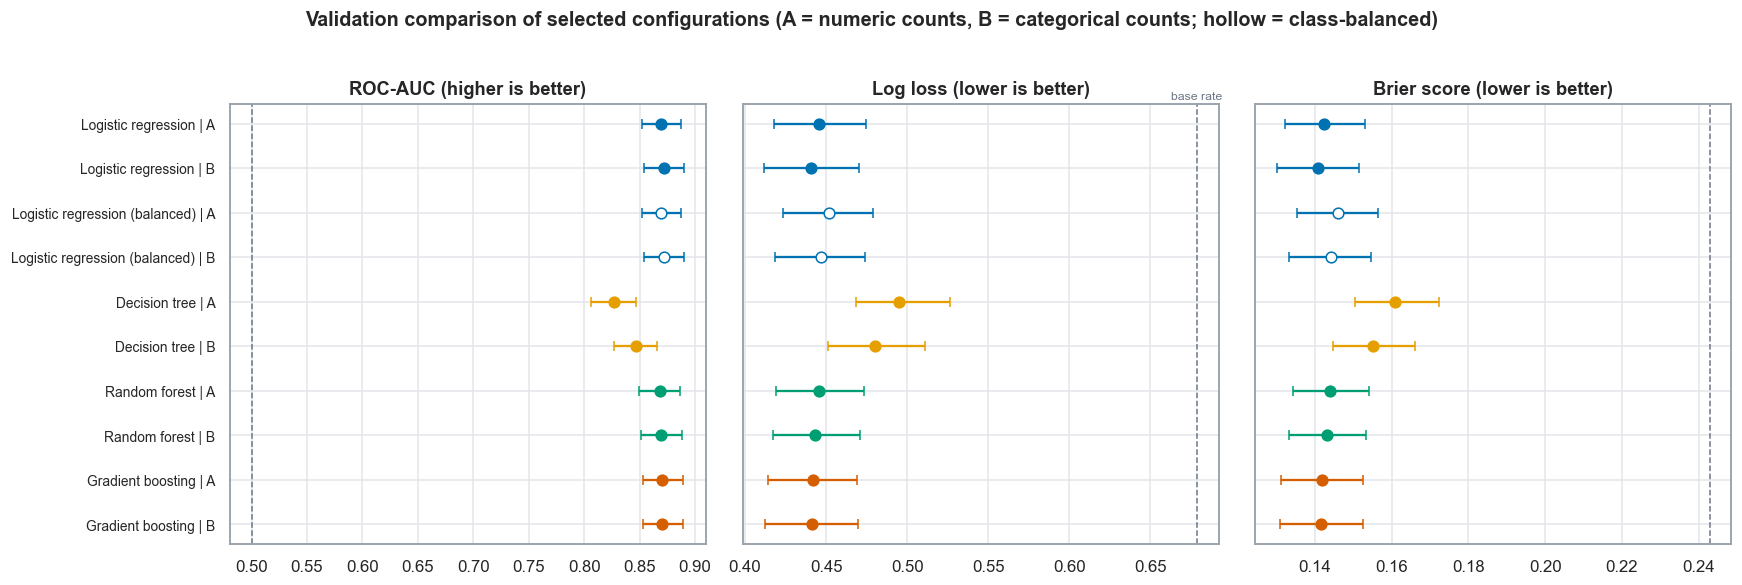

In [12]:
# Model comparison plot (point estimate +/- 95% bootstrap CI); hollow markers = class-balanced comparison models
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
rr = results[results.model_id != "DUMMY"].reset_index(drop=True); yy = np.arange(len(rr))[::-1]
labels = [f"{r['Model']} | {r['model_id'].split('_')[1]}" for _, r in rr.iterrows()]
for ax, (m, lo, hi, title, ref) in zip(axes, [("roc_auc", "auc_ci_lo", "auc_ci_hi", "ROC-AUC (higher is better)", 0.5),
                                                ("log_loss", "ll_ci_lo", "ll_ci_hi", "Log loss (lower is better)", base_val["log_loss"]),
                                                ("brier", "brier_ci_lo", "brier_ci_hi", "Brier score (lower is better)", base_val["brier"])]):
    for yi, (_, r) in zip(yy, rr.iterrows()):
        fam = r.model_id.split("_")[0]; hollow = r.model_id.endswith("balanced")
        ax.errorbar(r[m], yi, xerr=[[r[m] - r[lo]], [r[hi] - r[m]]], fmt="o", color=FAM_C[fam], ecolor=FAM_C[fam], mfc="white" if hollow else FAM_C[fam], capsize=3, ms=7)
    ax.axvline(ref, color=NEUTRAL, ls="--", lw=1); ax.set_title(title); ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=9)
axes[1].text(base_val["log_loss"], yy.max() + 0.55, "base rate", fontsize=8, color=NEUTRAL, ha="center")
fig.suptitle("Validation comparison of selected configurations (A = numeric counts, B = categorical counts; hollow = class-balanced)", y=1.02, fontsize=13, fontweight="semibold")
savefig(fig, "model_01_comparison")

## 9. ROC curves, confusion matrices and probability distributions (validation)

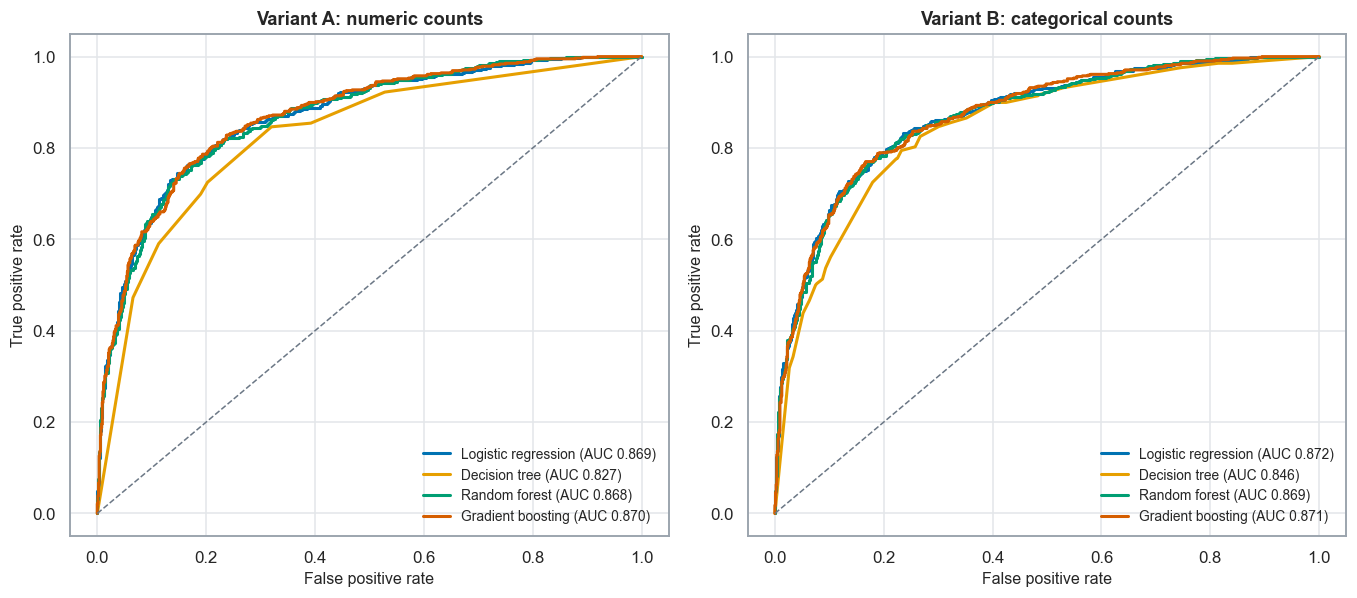

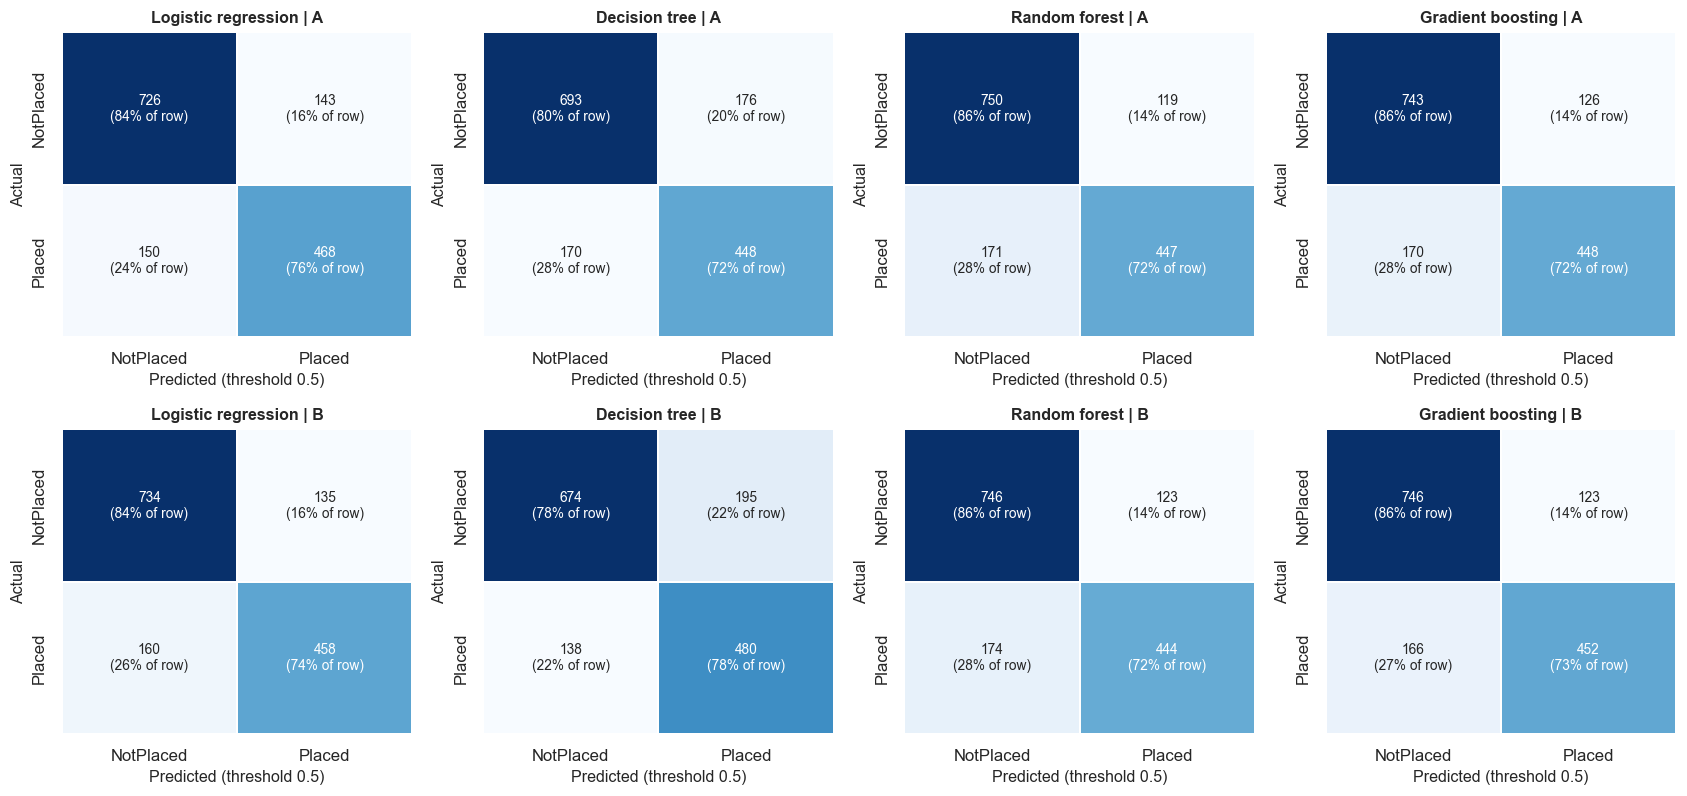

In [13]:
core = [m for m in order if not m.endswith("balanced")]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
for ax, v in zip(axes, ["A", "B"]):
    for fam in ["LR", "DT", "RF", "GB"]:
        r = REG[f"{fam}_{v}"]; fpr, tpr, _ = roc_curve(y_val, r["p_val"]); auc = roc_auc_score(y_val, r["p_val"])
        ax.plot(fpr, tpr, color=FAM_C[fam], lw=2, label=f"{r['label']} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title("Variant A: numeric counts" if v == "A" else "Variant B: categorical counts"); ax.legend(frameon=False, loc="lower right", fontsize=9)
savefig(fig, "model_02_validation_roc")

fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.4)); cm_rows = []
for ax, mid in zip(axes.ravel(), [f"{f}_{v}" for v in ["A", "B"] for f in ["LR", "DT", "RF", "GB"]]):
    pred = (REG[mid]["p_val"] >= 0.5).astype(int); cm = confusion_matrix(y_val, pred, labels=[0, 1])
    for i, a in enumerate(["NotPlaced", "Placed"]):
        for j, b in enumerate(["NotPlaced", "Placed"]): cm_rows.append({"model_id": mid, "actual": a, "predicted": b, "count": int(cm[i, j])})
    ann = np.array([[f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.0f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=ann, fmt="", cmap="Blues", cbar=False, ax=ax, xticklabels=["NotPlaced", "Placed"], yticklabels=["NotPlaced", "Placed"], linewidths=1, linecolor="white", annot_kws={"fontsize": 9})
    ax.set_title(f"{REG[mid]['label']} | {mid[-1]}", fontsize=10.5); ax.set_xlabel("Predicted (threshold 0.5)"); ax.set_ylabel("Actual")
pd.DataFrame(cm_rows).to_csv(MET / "05_confusion_matrices.csv", index=False)
savefig(fig, "model_03_confusion_matrices")

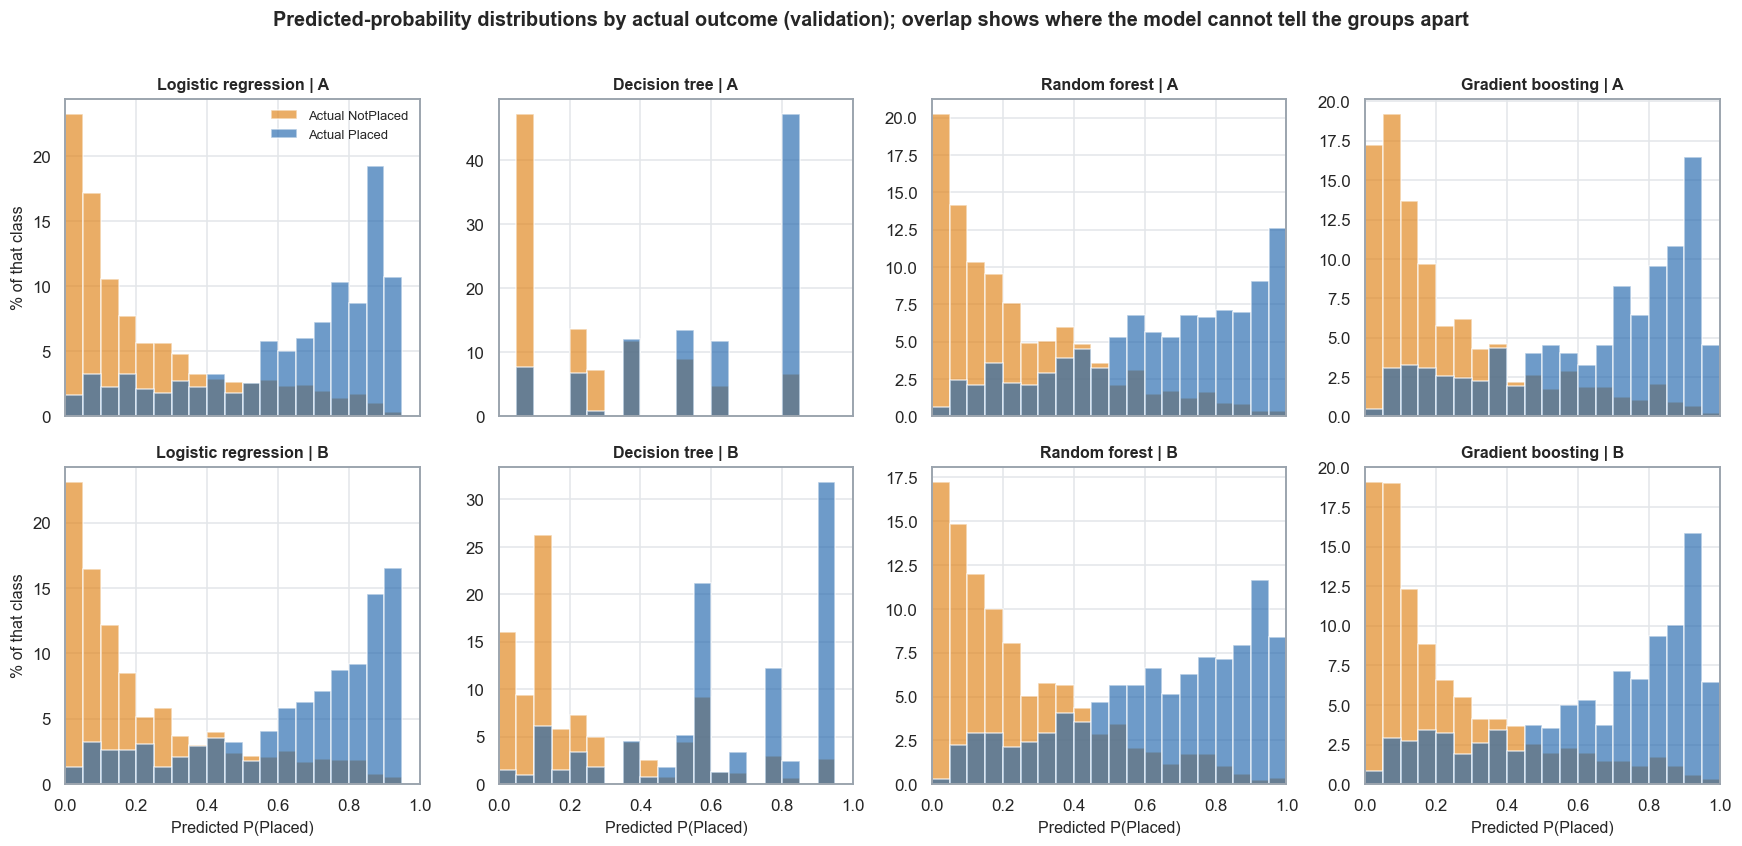

,overlap_coefficient,median_p_placed,median_p_notplaced,share_uncertain_0.2_0.8_%,share_extreme_<0.02_or_>0.98_%,mean_pred,observed_rate
model_id,,,,,,,
LR_A,0.404,0.742,0.140,43.510,4.169,0.410,0.416
DT_A,0.474,0.622,0.236,45.730,0.000,0.412,0.416
RF_A,0.414,0.691,0.173,48.352,6.052,0.411,0.416
GB_A,0.406,0.735,0.149,41.426,0.538,0.410,0.416
LR_B,0.402,0.746,0.140,42.098,4.102,0.410,0.416
DT_B,0.438,0.651,0.117,45.999,0.000,0.410,0.416
RF_B,0.405,0.691,0.178,49.025,2.892,0.410,0.416
GB_B,0.398,0.738,0.147,41.695,1.681,0.411,0.416


In [14]:
BINS = np.linspace(0, 1, 21); prob_rows = []
fig, axes = plt.subplots(2, 4, figsize=(16, 7.6), sharex=True)
for ax, mid in zip(axes.ravel(), [f"{f}_{v}" for v in ["A", "B"] for f in ["LR", "DT", "RF", "GB"]]):
    p = REG[mid]["p_val"]
    hp, _ = np.histogram(p[y_val == 1], BINS); hn, _ = np.histogram(p[y_val == 0], BINS)
    wp, wn = hp / hp.sum(), hn / hn.sum()
    ax.bar(BINS[:-1], wn * 100, width=0.05, align="edge", color=NOT_C, alpha=0.65, label="Actual NotPlaced")
    ax.bar(BINS[:-1], wp * 100, width=0.05, align="edge", color=PLACED_C, alpha=0.65, label="Actual Placed")
    ax.set_title(f"{REG[mid]['label']} | {mid[-1]}", fontsize=10.5); ax.set_xlim(0, 1)
    prob_rows.append({"model_id": mid, "overlap_coefficient": float(np.minimum(wp, wn).sum()), "median_p_placed": float(np.median(p[y_val == 1])),
                      "median_p_notplaced": float(np.median(p[y_val == 0])), "share_uncertain_0.2_0.8_%": float(((p > 0.2) & (p < 0.8)).mean() * 100),
                      "share_extreme_<0.02_or_>0.98_%": float(((p < 0.02) | (p > 0.98)).mean() * 100), "mean_pred": float(p.mean()), "observed_rate": float(y_val.mean())})
for ax in axes[:, 0]: ax.set_ylabel("% of that class")
for ax in axes[1]: ax.set_xlabel("Predicted P(Placed)")
axes[0, 0].legend(frameon=False, fontsize=8.5)
fig.suptitle("Predicted-probability distributions by actual outcome (validation); overlap shows where the model cannot tell the groups apart", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "model_04_probability_distributions")
prob = pd.DataFrame(prob_rows).set_index("model_id"); prob.to_csv(MET / "05_probability_diagnostics.csv"); prob.round(3)

**Reading the probability plots.** Less overlap between the two histograms means the model ranks Placed students above NotPlaced students more reliably, but even well-separated distributions do **not** mean perfect prediction: the overlap coefficient above quantifies the shared region, the "uncertain" share lists students given probabilities between 0.2 and 0.8, and extreme probabilities from flexible models can reflect over-confidence rather than accuracy (calibration is examined in Phase 5).

## 10. Logistic-regression coefficients
Coefficients are log-odds changes. **Numeric predictors are standardised, so one unit = one training-set standard deviation** (`train_sd` is given so effects per original unit can be derived: `OR_per_original_unit = exp(coef / train_sd)`).
One-hot coefficients are contrasts with the **reference** level named in the table. Wording: "holding the other model variables constant, the fitted model associates ... with ..."; these are associations in observational data, **not causal effects**. The L2 penalty shrinks coefficients slightly, and no standard errors/CIs are reported for the penalised fit.

In [15]:
coef_rows = []
for mid in ["LR_A", "LR_B", "LR_A_balanced", "LR_B_balanced"]:
    pipe = REG[mid]["pipe"]; prep, lr = pipe.named_steps["prep"], pipe.named_steps["model"]
    names = list(prep.get_feature_names_out()); sc = prep.named_transformers_["num"]; sd = dict(zip(sc.feature_names_in_, sc.scale_))
    for nme, b in zip(names, lr.coef_[0]):
        if nme in sd: unit, ref, tsd = "per 1 SD (train)", "-", sd[nme]
        else:
            base = next(f for f in FEATURES if nme.startswith(f + "_")); lvl = nme[len(base) + 1:]
            ref = "No" if base in BIN else str(REFS[base]); unit, tsd = f"{base}={lvl} vs {ref}", np.nan
        coef_rows.append({"model_id": mid, "feature": nme, "coefficient": b, "odds_ratio": np.exp(b), "unit": unit, "reference_level": ref, "train_sd": tsd,
                          "odds_ratio_per_original_unit": np.exp(b / tsd) if not np.isnan(tsd) else np.nan})
    coef_rows.append({"model_id": mid, "feature": "(intercept)", "coefficient": lr.intercept_[0], "odds_ratio": np.exp(lr.intercept_[0]), "unit": "baseline log-odds at reference/mean profile",
                      "reference_level": "-", "train_sd": np.nan, "odds_ratio_per_original_unit": np.nan})
coefs = pd.DataFrame(coef_rows); coefs.to_csv(MET / "05_logistic_coefficients.csv", index=False)
for mid in ["LR_A", "LR_B"]:
    print(f"=== {mid} ({REG[mid]['label']}; {'numeric' if mid.endswith('A') else 'categorical'} counts) ===")
    display(coefs[coefs.model_id == mid].drop(columns="model_id").set_index("feature").round(3))

=== LR_A (Logistic regression; numeric counts) ===


,coefficient,odds_ratio,unit,reference_level,train_sd,odds_ratio_per_original_unit
feature,,,,,,
CGPA,0.278,1.320,per 1 SD (train),-,0.638,1.545
AptitudeTestScore,0.556,1.743,per 1 SD (train),-,8.164,1.070
SoftSkillsRating,0.292,1.339,per 1 SD (train),-,0.413,2.026
SSC_Marks,0.317,1.373,per 1 SD (train),-,10.361,1.031
HSC_Marks,0.232,1.261,per 1 SD (train),-,8.893,1.026
Internships,0.014,1.014,per 1 SD (train),-,0.662,1.021
Projects,0.193,1.212,per 1 SD (train),-,0.867,1.249
Workshops/Certifications,0.132,1.142,per 1 SD (train),-,0.906,1.157
ExtracurricularActivities_Yes,0.693,1.999,ExtracurricularActivities=Yes vs No,No,NaN,NaN


=== LR_B (Logistic regression; categorical counts) ===


,coefficient,odds_ratio,unit,reference_level,train_sd,odds_ratio_per_original_unit
feature,,,,,,
CGPA,0.256,1.292,per 1 SD (train),-,0.638,1.494
AptitudeTestScore,0.500,1.649,per 1 SD (train),-,8.164,1.063
SoftSkillsRating,0.280,1.324,per 1 SD (train),-,0.413,1.970
SSC_Marks,0.286,1.332,per 1 SD (train),-,10.361,1.028
HSC_Marks,0.209,1.232,per 1 SD (train),-,8.893,1.024
Internships_0,0.232,1.261,Internships=0 vs 1,1,NaN,NaN
Internships_2,0.226,1.254,Internships=2 vs 1,1,NaN,NaN
Projects_0,0.504,1.655,Projects=0 vs 3,3,NaN,NaN
Projects_1,-0.414,0.661,Projects=1 vs 3,3,NaN,NaN


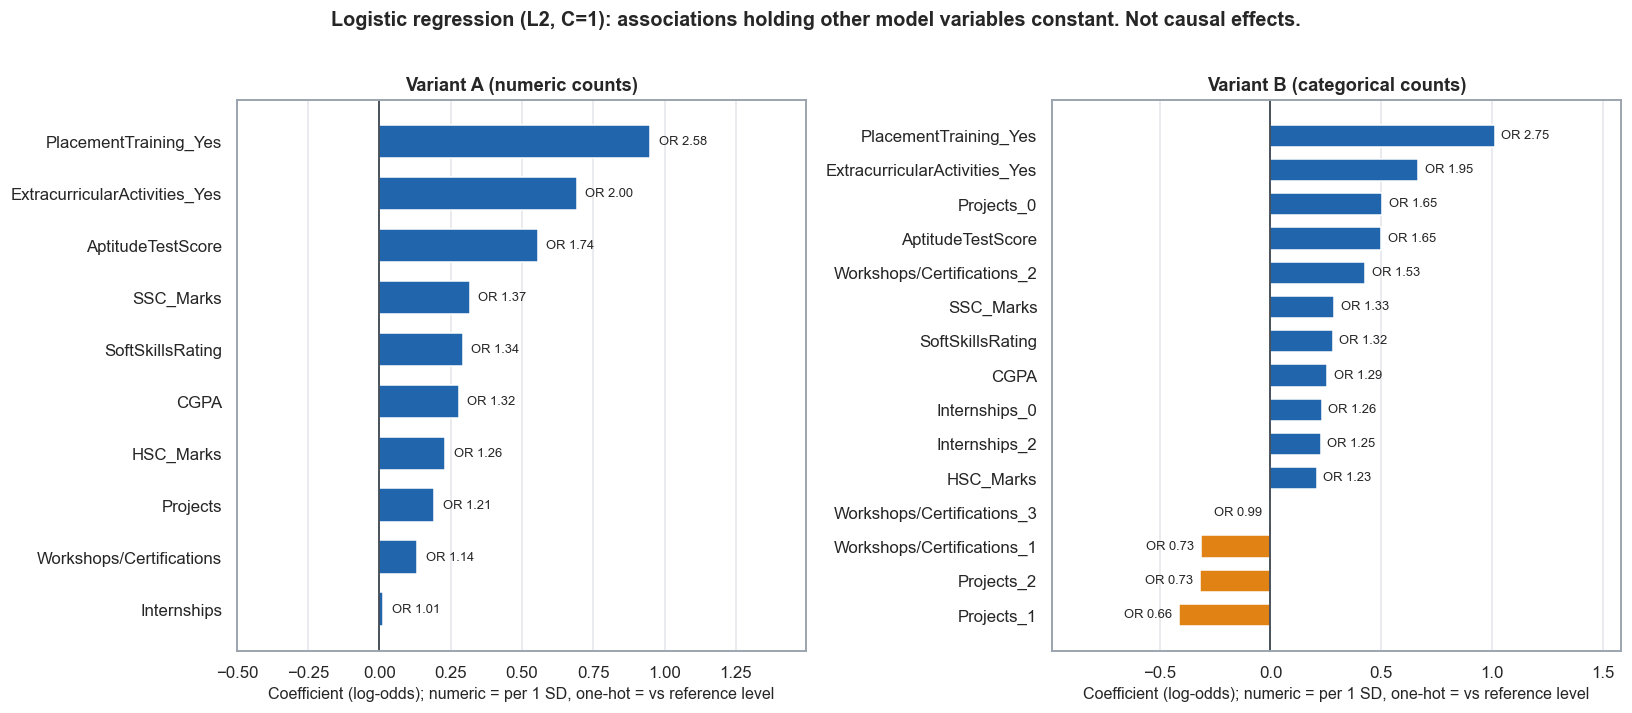

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
for ax, mid, ttl in zip(axes, ["LR_A", "LR_B"], ["Variant A (numeric counts)", "Variant B (categorical counts)"]):
    d = coefs[(coefs.model_id == mid) & (coefs.feature != "(intercept)")].sort_values("coefficient")
    cols_ = [PLACED_C if b > 0 else NOT_C for b in d.coefficient]
    ax.barh(d.feature, d.coefficient, color=cols_, height=0.65)
    for yi, (b, o) in enumerate(zip(d.coefficient, d.odds_ratio)): ax.text(b + (0.03 if b >= 0 else -0.03), yi, f"OR {o:.2f}", va="center", ha="left" if b >= 0 else "right", fontsize=8.5)
    ax.axvline(0, color="#1d2733", lw=1); ax.set_xlabel("Coefficient (log-odds); numeric = per 1 SD, one-hot = vs reference level"); ax.set_title(ttl); ax.grid(axis="y", visible=False)
    lo_, hi_ = ax.get_xlim(); ax.set_xlim(lo_ - 0.5, hi_ + 0.5)
fig.suptitle("Logistic regression (L2, C=1): associations holding other model variables constant. Not causal effects.", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "model_05_logistic_coefficients")

## 11. Tree-model feature importance
Impurity-based (mean decrease in impurity) importances from the selected decision tree, random forest and gradient boosting models, shown per encoded column and **aggregated back to the original predictor** (sum over one-hot levels).
These describe how heavily a fitted model *uses* a feature; they are **not causal**, are biased towards features with many distinct values, and are shared among correlated predictors. Permutation importance or SHAP can be used later for stronger interpretation.

model_id,DT_A,RF_A,GB_A,DT_B,RF_B,GB_B
feature,,,,,,
AptitudeTestScore,0.174,0.188,0.203,0.163,0.169,0.175
CGPA,0.017,0.083,0.063,0.026,0.093,0.064
ExtracurricularActivities,0.118,0.145,0.096,0.126,0.126,0.122
HSC_Marks,0.665,0.216,0.249,0.585,0.182,0.244
Internships,0.000,0.011,0.002,0.000,0.020,0.002
PlacementTraining,0.000,0.027,0.046,0.032,0.031,0.046
Projects,0.000,0.103,0.138,0.008,0.122,0.142
SSC_Marks,0.000,0.109,0.101,0.014,0.111,0.098
SoftSkillsRating,0.000,0.052,0.029,0.012,0.063,0.029


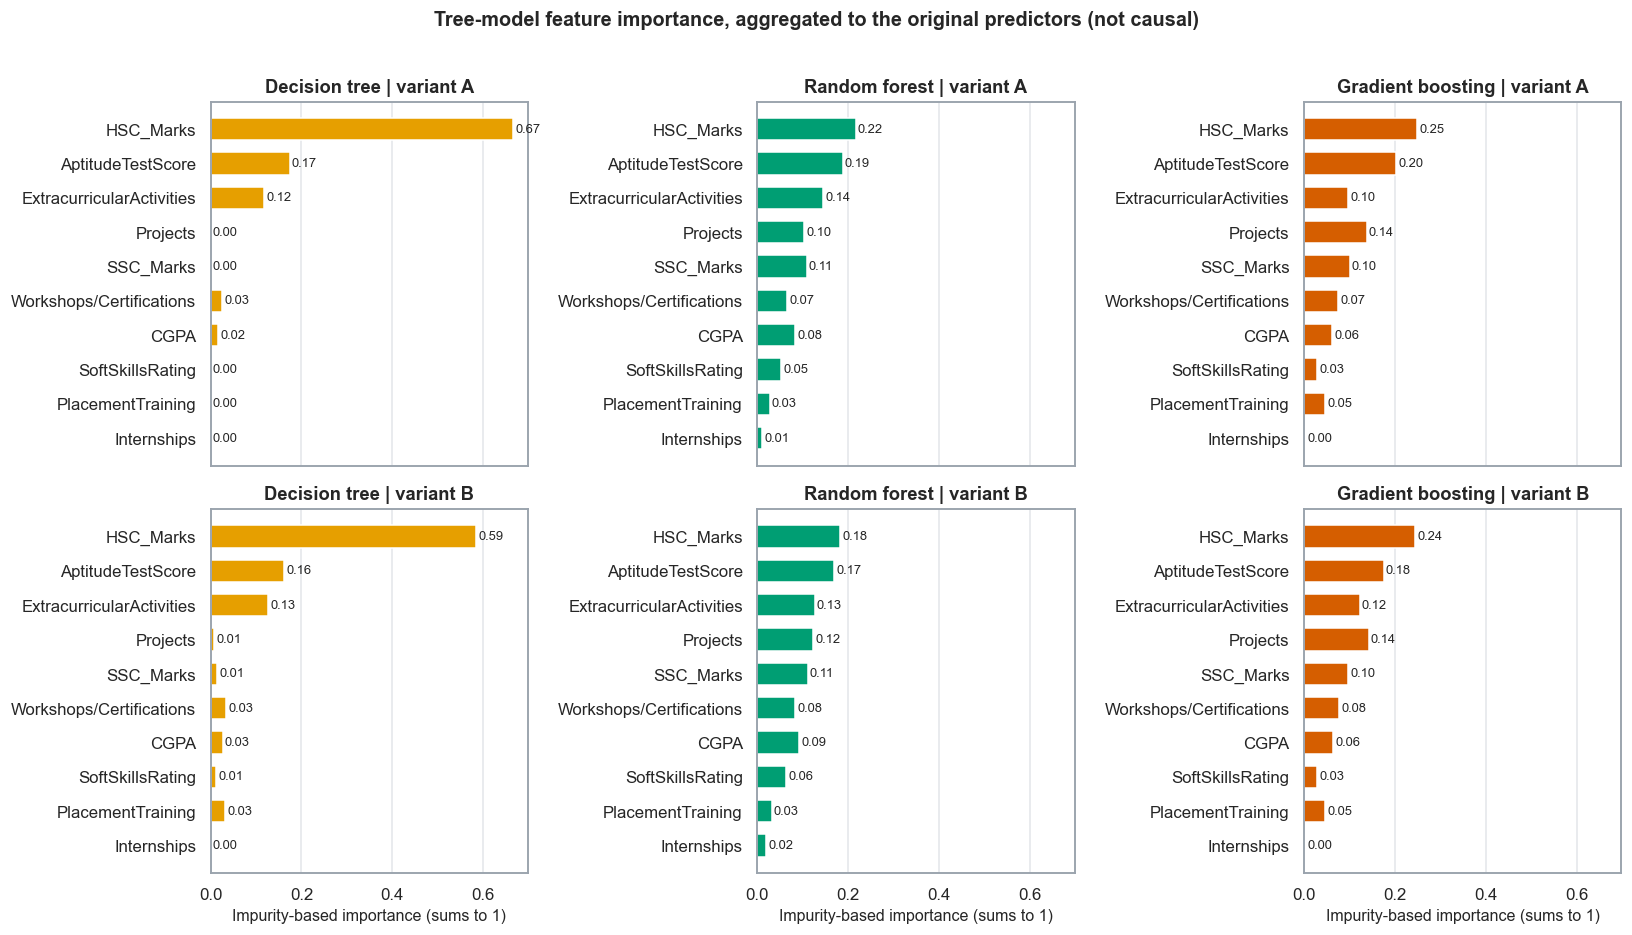

In [17]:
def original_of(name): return next(f for f in FEATURES if name == f or name.startswith(f + "_"))
imp_rows = []
for mid in [f"{f}_{v}" for f in ["DT", "RF", "GB"] for v in ["A", "B"]]:
    pipe = REG[mid]["pipe"]; names = pipe.named_steps["prep"].get_feature_names_out(); imp = pipe.named_steps["model"].feature_importances_
    for n_, i_ in zip(names, imp): imp_rows.append({"model_id": mid, "level": "encoded", "feature": n_, "original_feature": original_of(n_), "importance": i_})
    for f_, s_ in pd.Series(imp, index=[original_of(n_) for n_ in names]).groupby(level=0).sum().items():
        imp_rows.append({"model_id": mid, "level": "original", "feature": f_, "original_feature": f_, "importance": s_})
imp_df = pd.DataFrame(imp_rows); imp_df.to_csv(MET / "05_tree_feature_importance.csv", index=False)
agg = imp_df[imp_df.level == "original"].pivot(index="feature", columns="model_id", values="importance")[[f"{f}_{v}" for v in ["A", "B"] for f in ["DT", "RF", "GB"]]]
display(agg.round(3))
fig, axes = plt.subplots(2, 3, figsize=(15, 8.4), sharex=True)
ordr = agg.mean(axis=1).sort_values().index
for ax, mid in zip(axes.ravel(), agg.columns):
    ax.barh(ordr, agg.loc[ordr, mid], color=FAM_C[mid.split("_")[0]], height=0.65)
    for yi, v in enumerate(agg.loc[ordr, mid]): ax.text(v + 0.005, yi, f"{v:.2f}", va="center", fontsize=8.5)
    ax.set_title(f"{REG[mid]['label']} | variant {mid[-1]}"); ax.grid(axis="y", visible=False)
for ax in axes[1]: ax.set_xlabel("Impurity-based importance (sums to 1)")
fig.suptitle("Tree-model feature importance, aggregated to the original predictors (not causal)", y=1.01, fontsize=13, fontweight="semibold")
savefig(fig, "model_06_tree_feature_importance")

## 12. Overfitting check (train vs validation)
Heuristic flags (not statistical tests): **suspicious** if the ROC-AUC gap (train - validation) exceeds 0.03 or the log-loss gap (validation - train) exceeds 0.05; **large** if the AUC gap exceeds 0.05 or the log-loss gap exceeds 0.10. A high training score never drives selection.

In [18]:
og = []
for mid in order:
    r = REG[mid]; mt, mv = evaluate(r["p_train"], y_train), evaluate(r["p_val"], y_val)
    ag, lg = mt["roc_auc"] - mv["roc_auc"], mv["log_loss"] - mt["log_loss"]
    flag = "large" if (ag > 0.05 or lg > 0.10) else "suspicious" if (ag > 0.03 or lg > 0.05) else "ok"
    og.append({"model_id": mid, "Model": r["label"], "Representation": r["variant"], "train_roc_auc": mt["roc_auc"], "val_roc_auc": mv["roc_auc"], "auc_gap": ag,
               "train_log_loss": mt["log_loss"], "val_log_loss": mv["log_loss"], "log_loss_gap": lg, "train_brier": mt["brier"], "val_brier": mv["brier"], "flag": flag})
gap = pd.DataFrame(og); gap.to_csv(MET / "05_train_validation_comparison.csv", index=False)
gap.drop(columns=["Model"]).set_index("model_id").round(4)

,Representation,train_roc_auc,val_roc_auc,auc_gap,train_log_loss,val_log_loss,log_loss_gap,train_brier,val_brier,flag
model_id,,,,,,,,,,
LR_A,A,0.8777,0.8694,0.0083,0.4336,0.4457,0.0121,0.1400,0.1424,ok
LR_B,B,0.8807,0.8717,0.0089,0.4280,0.4408,0.0128,0.1382,0.1409,ok
LR_A_balanced,A,0.8777,0.8694,0.0083,0.4418,0.4520,0.0102,0.1436,0.1461,ok
LR_B_balanced,B,0.8807,0.8718,0.0089,0.4361,0.4469,0.0108,0.1415,0.1442,ok
DT_A,A,0.8435,0.8273,0.0162,0.4750,0.4953,0.0202,0.1540,0.1608,ok
DT_B,B,0.8703,0.8464,0.0238,0.4393,0.4799,0.0407,0.1414,0.1551,ok
RF_A,A,0.9240,0.8680,0.0560,0.3569,0.4454,0.0885,0.1128,0.1440,large
RF_B,B,0.9133,0.8693,0.0440,0.3771,0.4432,0.0660,0.1191,0.1431,suspicious
GB_A,A,0.8872,0.8704,0.0168,0.4167,0.4417,0.0250,0.1340,0.1418,ok


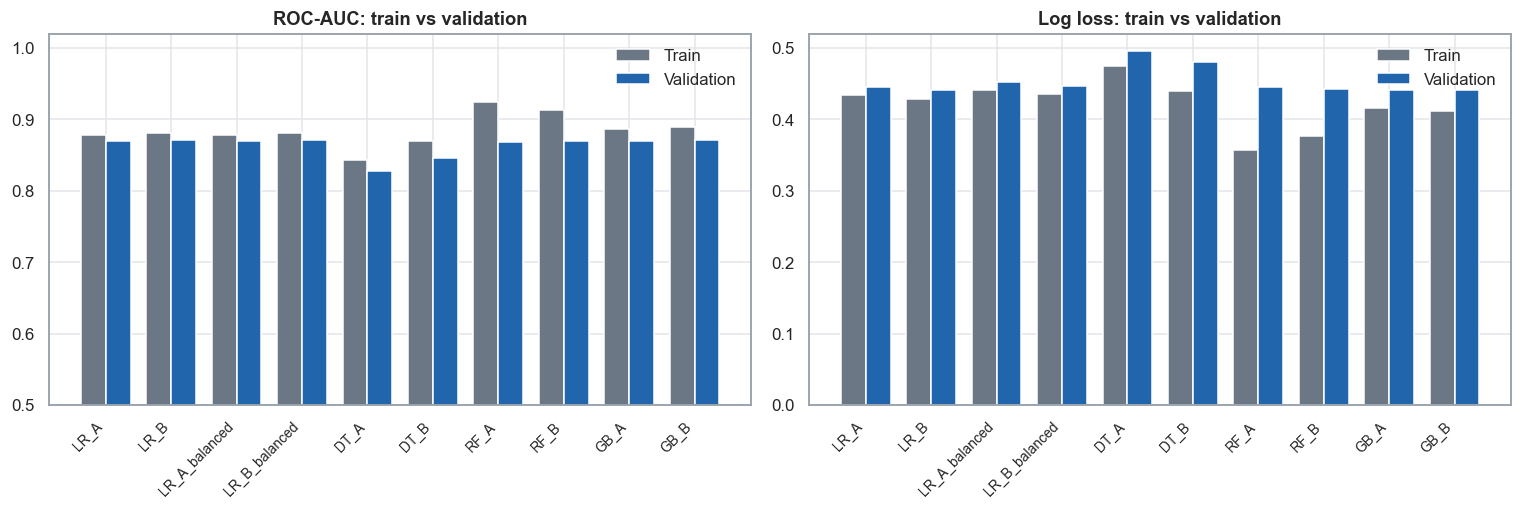

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); x = np.arange(len(gap)); w = 0.38
for ax, (a, b, ttl) in zip(axes, [("train_roc_auc", "val_roc_auc", "ROC-AUC"), ("train_log_loss", "val_log_loss", "Log loss")]):
    ax.bar(x - w / 2, gap[a], w, color=NEUTRAL, label="Train"); ax.bar(x + w / 2, gap[b], w, color=PLACED_C, label="Validation")
    ax.set_xticks(x); ax.set_xticklabels(gap.model_id, rotation=45, ha="right", fontsize=9); ax.set_title(f"{ttl}: train vs validation"); ax.legend(frameon=False)
    if ttl == "ROC-AUC": ax.set_ylim(0.5, 1.02)
savefig(fig, "model_07_train_vs_validation")

## 13. Numeric (A) vs categorical (B) count representation
For each model family at its selected configuration: B minus A for ROC-AUC and log loss, with **paired** bootstrap 95% CIs (same validation resamples). A CI that includes 0 means the data do not distinguish the two representations.

In [20]:
comp = []
for fam in ["LR", "LR_balanced", "DT", "RF", "GB"]:
    a, b = (f"LR_A_balanced", f"LR_B_balanced") if fam == "LR_balanced" else (f"{fam}_A", f"{fam}_B")
    dll, dauc, dbr = BOOT[b]["ll"] - BOOT[a]["ll"], BOOT[b]["auc"] - BOOT[a]["auc"], BOOT[b]["brier"] - BOOT[a]["brier"]
    ra, rb = results.set_index("model_id").loc[a], results.set_index("model_id").loc[b]
    comp.append({"family": fam, "AUC_A": ra.roc_auc, "AUC_B": rb.roc_auc, "dAUC_(B-A)": rb.roc_auc - ra.roc_auc, "dAUC_ci_lo": ci(dauc)[0], "dAUC_ci_hi": ci(dauc)[1],
                 "LL_A": ra.log_loss, "LL_B": rb.log_loss, "dLL_(B-A)": rb.log_loss - ra.log_loss, "dLL_ci_lo": ci(dll)[0], "dLL_ci_hi": ci(dll)[1],
                 "dBrier_(B-A)": rb.brier - ra.brier, "dBrier_ci_lo": ci(dbr)[0], "dBrier_ci_hi": ci(dbr)[1],
                 "B_distinguishable_from_A_on_logloss": not (ci(dll)[0] <= 0 <= ci(dll)[1])})
comp = pd.DataFrame(comp); comp.to_csv(MET / "05_variant_A_vs_B.csv", index=False); comp.set_index("family").round(4)

,AUC_A,AUC_B,dAUC_(B-A),dAUC_ci_lo,dAUC_ci_hi,LL_A,LL_B,dLL_(B-A),dLL_ci_lo,dLL_ci_hi,dBrier_(B-A),dBrier_ci_lo,dBrier_ci_hi,B_distinguishable_from_A_on_logloss
family,,,,,,,,,,,,,,
LR,0.8694,0.8717,0.0023,-0.0008,0.0058,0.4457,0.4408,-0.0049,-0.0099,0.0001,-0.0015,-0.0035,0.0004,False
LR_balanced,0.8694,0.8718,0.0024,-0.0007,0.0058,0.4520,0.4469,-0.0051,-0.0104,-0.0001,-0.0019,-0.0040,0.0001,True
DT,0.8273,0.8464,0.0192,0.0098,0.0283,0.4953,0.4799,-0.0153,-0.0297,-0.0013,-0.0057,-0.0110,-0.0003,True
RF,0.8680,0.8693,0.0013,-0.0009,0.0035,0.4454,0.4432,-0.0022,-0.0058,0.0011,-0.0009,-0.0020,0.0002,False
GB,0.8704,0.8706,0.0003,-0.0013,0.0019,0.4417,0.4413,-0.0004,-0.0027,0.0022,-0.0001,-0.0011,0.0010,False


## 14. Provisional model selection (VALIDATION ONLY)
**Rule, fixed before looking at the final ranking.**
1. **Eligibility:** exclude the class-balanced comparison models (they intentionally distort probabilities); exclude models with a **large** train-validation gap (section 12); exclude models whose mean predicted probability differs from the observed validation rate by more than 3 percentage points (probabilities must be sensible).
2. **Primary comparison:** among eligible models find the one with the lowest validation log loss (the proper scoring rule closest to the project's purpose). Every eligible model whose paired-bootstrap 95% CI for (log loss minus best log loss) includes 0 is *statistically indistinguishable* from the best on this validation set.
3. **Tie-break within the indistinguishable set:** prefer the more interpretable family (logistic regression, then decision tree, then gradient boosting / random forest), then lower log loss. ROC-AUC and Brier score are inspected for agreement; F1/recall at 0.5 serve as a sanity check, not a deciding criterion.
This selection is provisional: it uses a single validation split of 1,487 students, and the search was also run on this split, so validation scores of the chosen model are slightly optimistic. Phase 5 should confirm with cross-validation on the training data and examine calibration.

In [21]:
rk = {"LR": 1, "DT": 2, "GB": 3, "RF": 3}
R = results.set_index("model_id").join(gap.set_index("model_id")[["auc_gap", "log_loss_gap", "flag"]])
elig = R.loc[[m for m in order if not m.endswith("balanced")]].copy()
elig["prob_sane"] = (elig.mean_pred - elig.observed_rate).abs() <= 0.03
elig["eligible"] = (elig.flag != "large") & elig.prob_sane
print("Eligibility:"); display(elig[["flag", "prob_sane", "eligible", "log_loss", "roc_auc", "brier"]].round(4))
E = elig[elig.eligible]; best = E.log_loss.idxmin()
sel_rows = []
for m in E.index:
    d = BOOT[m]["ll"] - BOOT[best]["ll"]; lo, hi = ci(d)
    sel_rows.append({"model_id": m, "log_loss": E.loc[m, "log_loss"], "dLL_vs_best": E.loc[m, "log_loss"] - E.loc[best, "log_loss"], "ci_lo": lo, "ci_hi": hi,
                     "indistinguishable_from_best": lo <= 0, "interpretability_rank": rk[m.split("_")[0]], "roc_auc": E.loc[m, "roc_auc"], "brier": E.loc[m, "brier"],
                     "f1": E.loc[m, "f1"], "recall": E.loc[m, "recall"]})
sel = pd.DataFrame(sel_rows).set_index("model_id")
cand = sel[sel.indistinguishable_from_best].sort_values(["interpretability_rank", "log_loss"])
chosen = cand.index[0]
print(f"\nBest validation log loss among eligible models: {best}")
display(sel.round(4))
print(f"\nStatistically indistinguishable from best: {list(cand.index)}")
print(f"PROVISIONAL SELECTION -> {chosen}: {REG[chosen]['label']}, {'numeric' if REG[chosen]['variant']=='A' else 'categorical'} counts, config {cfg_text(REG[chosen])}")

Eligibility:


,flag,prob_sane,eligible,log_loss,roc_auc,brier
model_id,,,,,,
LR_A,ok,True,True,0.4457,0.8694,0.1424
LR_B,ok,True,True,0.4408,0.8717,0.1409
DT_A,ok,True,True,0.4953,0.8273,0.1608
DT_B,ok,True,True,0.4799,0.8464,0.1551
RF_A,large,True,False,0.4454,0.8680,0.1440
RF_B,suspicious,True,True,0.4432,0.8693,0.1431
GB_A,ok,True,True,0.4417,0.8704,0.1418
GB_B,ok,True,True,0.4413,0.8706,0.1417



Best validation log loss among eligible models: LR_B


,log_loss,dLL_vs_best,ci_lo,ci_hi,indistinguishable_from_best,interpretability_rank,roc_auc,brier,f1,recall
model_id,,,,,,,,,,
LR_A,0.4457,0.0049,-0.0001,0.0099,True,1,0.8694,0.1424,0.7616,0.7573
LR_B,0.4408,0.0000,0.0000,0.0000,True,1,0.8717,0.1409,0.7564,0.7411
DT_A,0.4953,0.0544,0.0385,0.0729,False,2,0.8273,0.1608,0.7214,0.7249
DT_B,0.4799,0.0391,0.0248,0.0549,False,2,0.8464,0.1551,0.7425,0.7767
RF_B,0.4432,0.0023,-0.0051,0.0098,True,3,0.8693,0.1431,0.7494,0.7184
GB_A,0.4417,0.0008,-0.0054,0.0068,True,3,0.8704,0.1418,0.7517,0.7249
GB_B,0.4413,0.0005,-0.0054,0.0065,True,3,0.8706,0.1417,0.7578,0.7314



Statistically indistinguishable from best: ['LR_B', 'LR_A', 'GB_B', 'GB_A', 'RF_B']
PROVISIONAL SELECTION -> LR_B: Logistic regression, categorical counts, config C=1.0, class_weight=None


In [22]:
r = results.set_index("model_id").loc[chosen]; g_ = gap.set_index("model_id").loc[chosen]
print(f"{chosen}: val ROC-AUC {r.roc_auc:.4f} [{r.auc_ci_lo:.4f}, {r.auc_ci_hi:.4f}] | log loss {r.log_loss:.4f} [{r.ll_ci_lo:.4f}, {r.ll_ci_hi:.4f}] | Brier {r.brier:.4f} (skill vs base rate {r.brier_skill_vs_base_rate:.3f})")
print(f"accuracy {r.accuracy:.4f}, precision {r.precision:.4f}, recall {r.recall:.4f}, F1 {r.f1:.4f}")
print(f"train-validation: AUC gap {g_.auc_gap:+.4f}, log-loss gap {g_.log_loss_gap:+.4f}, flag = {g_.flag}")
print(f"mean predicted {r.mean_pred:.3f} vs observed {r.observed_rate:.3f}")
write_json({"provisional_model_id": chosen, "label": REG[chosen]["label"], "variant": REG[chosen]["variant"], "config": REG[chosen]["config"],
           "selected_on": "validation only (train used for fitting; test never opened)", "rule": "lowest val log loss among eligible, statistically indistinguishable set, tie-break by interpretability",
           "indistinguishable_set": list(cand.index), "validation_log_loss": float(r.log_loss), "validation_roc_auc": float(r.roc_auc), "validation_brier": float(r.brier)},
          MET / "05_provisional_selection.json")

LR_B: val ROC-AUC 0.8717 [0.8543, 0.8904] | log loss 0.4408 [0.4119, 0.4703] | Brier 0.1409 (skill vs base rate 0.420)
accuracy 0.8016, precision 0.7723, recall 0.7411, F1 0.7564
train-validation: AUC gap +0.0089, log-loss gap +0.0128, flag = ok
mean predicted 0.410 vs observed 0.416


## 15. Save pipelines, configurations and prediction tables

In [23]:
for mid in order: joblib.dump(REG[mid]["pipe"], MODELS / f"{mid}.joblib")
joblib.dump(dummy, MODELS / "DUMMY_prior.joblib")
configs = {"seed": SEED, "sklearn_version": sklearn.__version__, "features": FEATURES, "target": TARGET, "target_encoding": {"Placed": 1, "NotPlaced": 0},
           "count_reference_levels_(LR)": REFS, "binary_reference_level": "No", "threshold": 0.5,
           "preprocessing": {"A": "StandardScaler on 5 scale vars + 3 counts; one-hot ExtracurricularActivities & PlacementTraining (drop No) [LR]; trees: unscaled",
                             "B": "StandardScaler on 5 scale vars; one-hot Internships/Projects/Workshops (drop train-mode level for LR; all levels for trees) + 2 binary [LR]"},
           "models": {mid: {"family": REG[mid]["family"], "variant": REG[mid]["variant"], "config": REG[mid]["config"]} for mid in order},
           "search_grids": {"LR_C_sensitivity": [0.01, 0.1, 1, 10, 100], "DT": dt_grid, "RF": rf_grid, "GB": gb_grid},
           "files": {mid: f"models/phase4/{mid}.joblib" for mid in order}}
write_json(configs, MODELS / "model_configs.json")
pd.DataFrame({"y_true": y_val, **{mid: REG[mid]["p_val"] for mid in order}}).to_csv(MET / "05_validation_predictions.csv", index=False)
# reload check: a saved pipeline reproduces its validation probabilities exactly
re_ = joblib.load(MODELS / f"{chosen}.joblib")
assert np.allclose(re_.predict_proba(X_val)[:, 1], REG[chosen]["p_val"]), "saved pipeline does not reproduce predictions"
print("Saved", len(order) + 1, "pipelines to", MODELS, "and reload check passed.")

Saved 11 pipelines to D:\Student-Placement-Prediction\student-placement-prediction\models\phase4 and reload check passed.


## 16. End-of-phase summary

> All numbers are **validation** results (n = 1,487; Placed rate 41.56%) at the default 0.5 threshold. The test set was never opened (asserted below). Everything is association/prediction, not causation. Because hyper-parameters and the provisional model were chosen on this same validation split, the chosen model's validation scores are slightly optimistic.

### A. Validation model comparison
| Model (selected config) | Rep. | ROC-AUC | Log loss | Brier | F1 | Recall | Accuracy |
|---|---|---|---|---|---|---|---|
| Logistic regression (C=1) | A numeric | 0.869 | 0.446 | 0.142 | 0.762 | 0.757 | 0.803 |
| **Logistic regression (C=1)** | **B categorical** | **0.872** | **0.441** | **0.141** | 0.756 | 0.741 | 0.802 |
| Decision tree (A: depth 3; B: depth 5, min leaf 5) | A / B | 0.827 / 0.846 | 0.495 / 0.480 | 0.161 / 0.155 | 0.721 / 0.743 | 0.725 / 0.777 | 0.767 / 0.776 |
| Random forest (300 trees) | A / B | 0.868 / 0.869 | 0.445 / 0.443 | 0.144 / 0.143 | 0.755 / 0.749 | 0.723 / 0.718 | 0.805 / 0.800 |
| Gradient boosting (depth 2) | A / B | 0.870 / 0.871 | 0.442 / 0.441 | 0.142 / 0.142 | 0.752 / 0.758 | 0.725 / 0.731 | 0.801 / 0.806 |
| Reference: always predict train rate | - | 0.500 | 0.679 | 0.243 | 0 | 0 | 0.584 |

- Logistic regression, random forest and gradient boosting are **practically tied**: ROC-AUC 0.868-0.872 and log loss 0.441-0.446, far inside each model's 95% bootstrap CI (for example AUC CI roughly 0.854-0.890, log loss 0.412-0.470). Only the single decision tree is clearly worse (log loss 0.48-0.50; paired CI for the gap to the best excludes 0).
- All models beat the base-rate reference substantially (Brier skill about 0.42 versus the base rate; log loss 0.44 versus 0.68). A random Placed student receives a higher predicted probability than a random NotPlaced student about 87% of the time.
- The class-balanced logistic regressions have the same AUC but slightly worse log loss and Brier (0.447-0.452 and 0.144-0.146) and lower precision; they trade precision for recall (0.79-0.80) by design and were kept as comparison only.
- Accuracy (about 0.80) is similar across the competitive models and is not the deciding metric.

### B. Numeric (A) vs categorical (B) count representation
Paired bootstrap, B minus A, at each family's selected configuration:
| Family | dAUC (95% CI) | dLog loss (95% CI) | Reading |
|---|---|---|---|
| Logistic regression | +0.002 (-0.001, +0.006) | -0.005 (-0.010, +0.000) | B slightly better; borderline, not clearly distinguishable |
| Decision tree | +0.019 (+0.010, +0.028) | -0.015 (-0.030, -0.001) | B clearly better |
| Random forest | +0.001 | -0.002 (-0.006, +0.001) | no distinguishable difference |
| Gradient boosting | +0.000 | -0.000 (-0.003, +0.002) | no distinguishable difference |
- Treating the counts as categories matters for the shallow tree, helps the logistic regression marginally (consistent with the non-monotonic Workshops/Projects patterns found in Phase 3), and is irrelevant for ensembles that can already split on thresholds.
- The effect is small relative to validation noise, so the representation decision is a mild preference, not a proven difference.

### C. Provisional model selection (validation only)
**Logistic regression with categorical counts (Variant B), L2, C = 1.0, no class weighting** (`models/phase4/LR_B.joblib`; selection record in `results/metrics/modeling/05_provisional_selection.json`).

### D. Why it was selected
Rule fixed in advance: among eligible models, take the lowest validation log loss, then treat all models whose paired-bootstrap CI for the log-loss difference includes 0 as tied and choose the most interpretable.
1. **ROC-AUC / log loss / Brier:** LR-B has the best log loss (0.4408) and Brier (0.1409) and the highest AUC among the non-balanced models (0.8717); gradient boosting (0.4413) and random forest (0.4432) are statistically indistinguishable.
2. **F1/recall:** F1 0.756 and recall 0.741 are in line with the other competitive models (sanity check only; threshold untuned).
3. **Train-validation gap:** smallest of the competitive models (AUC +0.009, log loss +0.013).
4. **Interpretability:** coefficients and odds ratios are directly readable, which matters for explaining a placement probability.
5. **Sensible probabilities:** mean predicted probability 0.410 versus observed 0.416; no pile-up of extreme probabilities beyond about 4% below 0.02 or above 0.98.
Nothing more complex earned its extra complexity on this validation split. This is provisional: it rests on one split of 1,487 students and a search run on the same split.

### E. Train-validation gap
| Model | Train AUC | Val AUC | AUC gap | Log-loss gap | Flag |
|---|---|---|---|---|---|
| LR-A / LR-B | 0.878 / 0.881 | 0.869 / 0.872 | 0.008 / 0.009 | 0.012 / 0.013 | ok |
| DT-A / DT-B | 0.844 / 0.870 | 0.827 / 0.846 | 0.016 / 0.024 | 0.020 / 0.041 | ok |
| GB-A / GB-B | 0.887 / 0.890 | 0.870 / 0.871 | 0.017 / 0.019 | 0.025 / 0.030 | ok |
| RF-B | 0.913 | 0.869 | 0.044 | 0.066 | suspicious |
| **RF-A** | 0.924 | 0.868 | **0.056** | **0.089** | **large (excluded)** |
The random forests memorise the training data more than the other models do (training AUC above 0.91) for no validation benefit; RF-A was excluded from selection. Unregularised deep decision trees (depth None, leaf 1) had validation log loss above 11, showing why probability quality and overfitting must be checked, not just accuracy.

### F. Probability-quality observations
- Predicted probabilities from LR, RF and GB are broad, not just near 0 or 1; about 41-49% of validation students receive a probability between 0.2 and 0.8, and the overlap coefficient between the Placed and NotPlaced distributions is about 0.40 for LR/GB. Even the best models therefore cannot cleanly separate the groups, and a high AUC does not mean near-perfect individual prediction.
- The decision tree produces a few coarse probability levels (leaf proportions), which explains its worse log loss and Brier score despite similar accuracy.
- Random forest places 3-6% of students at extreme probabilities (below 0.02 or above 0.98); whether that confidence is warranted cannot be judged from these metrics and needs the calibration analysis planned for Phase 5.
- Mean predicted probability is within 0.6 percentage points of the observed rate for every model.
- **Logistic-regression coefficients (associations, not causal effects):** holding the other model variables constant, the fitted model associates PlacementTraining = Yes (OR 2.7 vs No) and ExtracurricularActivities = Yes (OR 1.9 vs No) with higher placement odds, and one training-SD higher aptitude (OR 1.65), SSC (1.33), soft skills (1.32), CGPA (1.29) and HSC (1.23) with higher odds. With categorical counts, Workshops = 1 is associated with lower odds than Workshops = 0 (OR 0.73, reference 0), and Projects = 1 and 2 with lower odds than Projects = 3 (OR 0.66, 0.73); the Projects = 0 coefficient (OR 1.65 vs 3) rests on only 19 training students and should not be interpreted. Internships has little association once the other variables are held constant (numeric OR 1.01 per SD; categorical levels 0 and 2 both slightly above level 1), unlike its strong raw association in the EDA.
- **Tree importances (not causal):** aptitude, HSC marks and extracurricular activities carry most of the importance in the ensembles (aptitude about 0.17-0.20, HSC about 0.18-0.25, extracurricular about 0.10-0.15); Internships and PlacementTraining receive little tree importance. In the depth-3 tree, HSC marks account for about two thirds of the total impurity reduction.

### G. Remaining questions for Phase 5 / Phase 6
1. **Calibration:** how well calibrated is each model (reliability curves, calibration slope/intercept)? Would Platt or isotonic recalibration, fitted without the validation labels, improve log loss?
2. **Robustness of the selection:** does stratified cross-validation on the training data (with repeated folds) confirm that logistic regression, gradient boosting and random forest remain tied, and is the A-versus-B preference stable?
3. **Stronger interpretation:** permutation importance and/or SHAP (with correlated predictors in mind), and stability of logistic coefficients across resamples.
4. **Decision threshold:** if a classification rule is needed, which threshold balances precision and recall for the intended use? (Deferred; not tuned here.)
5. **Non-monotonic count effects:** do tree models gain from interactions (Extracurricular x Training, Projects x Workshops) that a main-effects logistic model misses? Would adding interactions to the logistic model close any gap?
6. **Performance ceiling and subgroup behaviour:** how do models perform within subgroups (e.g. top-profile region where conflicting labels were found, small levels such as Workshops = 3)? How much of the remaining error looks irreducible?
7. **Generalisation caveat:** results describe this single (possibly rule-generated) dataset; the held-out test set remains untouched for the one-time final evaluation in Phase 6.

## 17. Proof that the test set was not used

In [24]:
opened = [Path(p) for p in _OPENED if isinstance(p, str) and p.lower().endswith((".csv", ".parquet", ".json", ".joblib", ".pkl"))]
csv_read = sorted({p.name for p in opened if p.suffix == ".csv"})
print("CSV files opened during this notebook run:", csv_read)
assert "test.csv" not in [p.name.lower() for p in opened], "test.csv was opened (processed or raw)!"
assert not any("data" in p.parts and "raw" in p.parts for p in opened), "a raw data file was opened"
assert "modeling_dataset.csv" not in csv_read and "campus_recruitment_combined_flagged.csv" not in csv_read
assert set(c for c in csv_read if c in ("train.csv", "validation.csv")) == {"train.csv", "validation.csv"}
assert "X_test" not in globals() and "y_test" not in globals() and "test" not in globals()
print("ASSERTIONS PASSED: test.csv was never opened; all fitting used TRAIN and all selection used VALIDATION only.")

CSV files opened during this notebook run: ['05_confusion_matrices.csv', '05_logistic_coefficients.csv', '05_lr_C_sensitivity.csv', '05_probability_diagnostics.csv', '05_train_validation_comparison.csv', '05_tree_feature_importance.csv', '05_tuning_grids.csv', '05_validation_predictions.csv', '05_validation_results.csv', '05_variant_A_vs_B.csv', 'train.csv', 'validation.csv']
ASSERTIONS PASSED: test.csv was never opened; all fitting used TRAIN and all selection used VALIDATION only.
